# 02 · Models, alerts and explanations

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/consulting-financial-services/credit-downgrade-early-warning/notebooks/02_models_and_alerts.ipynb)

Two stages. First, an article model reads each news item and gives it a risk score: TF-IDF on words, word pairs and character n-grams (which also cope with German compounds), then logistic regression. Second, an issuer model combines those scores with the rating, outlook, financials, share price and keyword counts for each issuer and month, using gradient boosting.

Four versions are compared on the same test period, so it is clear what each source of information adds.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "consulting-financial-services/credit-downgrade-early-warning"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
else:
    here = Path.cwd()
    while not (here / "src" / "downgrade_ews").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 110)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: credit-downgrade-early-warning


In [2]:
from downgrade_ews import config as C, pipeline, features, models, explain, validation, reporting

tables = pipeline.load_tables()      # reads data/, or generates it if missing
run = pipeline.run(tables)           # text model, panel, four issuer models (about a minute)
print(f"{len(tables['news']):,} articles on {C.N_ISSUERS} issuers, {C.START} to {C.END}")

65,908 articles on 360 issuers, 2022-01 to 2026-09


## What the article model learned

Words and phrases with the largest weights, English and German. Masked tokens and filler words are left out.

In [3]:
display(explain.top_terms(run.text_model, 10, "en")[["term", "weight", "direction"]].reset_index(drop=True))
display(explain.top_terms(run.text_model, 8, "de")[["term", "weight", "direction"]].reset_index(drop=True))

,term,weight,direction
0,cash,0.431809,raises risk
1,to negative,0.329427,raises risk
2,negativ,0.261009,raises risk
3,ratingagentur senkt,0.213678,raises risk
4,selbst wurde,0.213678,raises risk
5,senkt ausblick,0.213678,raises risk
6,rating selbst,0.213678,raises risk
7,selbst,0.213678,raises risk
8,negativ eine,0.213678,raises risk
9,negativ gesenkt,0.213678,raises risk


,term,weight,direction
0,auf negativ,0.361788,raises risk
1,ausblick für,0.247594,raises risk
2,wurde bestätigt,0.213678,raises risk
3,gesenkt das,0.213678,raises risk
4,das rating,0.213678,raises risk
5,nächsten,0.208789,raises risk
6,liquidität,0.134484,raises risk
7,die anleihen,0.125242,raises risk
8,hauptversammlung,-0.174340,lowers risk
9,verschuldung,-0.161982,lowers risk


## Comparison on the test period

Each model except the outlook rule gets the same review budget: the 15 highest-scoring issuers each month. The outlook rule flags every issuer on negative outlook, about 39 a month.

In [4]:
run.evaluation

,model,roc_auc,pr_auc,brier,alerts_per_month,alert_precision,downgrades,caught,event_recall,median_lead_months
0,Outlook only,0.6360,0.0730,0.0363,39.4167,0.1311,65,30,0.4615,3.0
1,Ratings + financials,0.6400,0.0814,0.0373,15.0000,0.1333,65,15,0.2308,3.0
2,+ keyword rules,0.7300,0.1869,0.0345,15.0000,0.2500,65,27,0.4154,2.0
3,+ NLP news scores,0.7779,0.2577,0.0331,15.0000,0.2889,65,32,0.4923,2.0


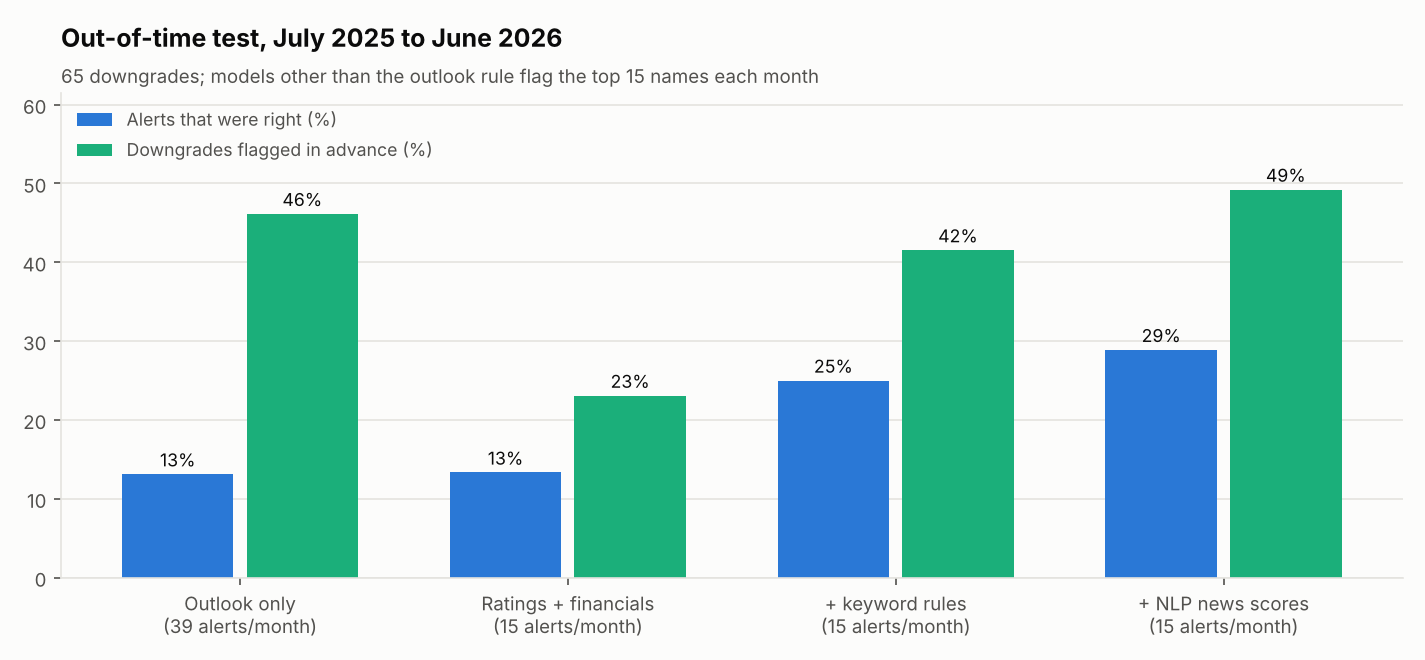

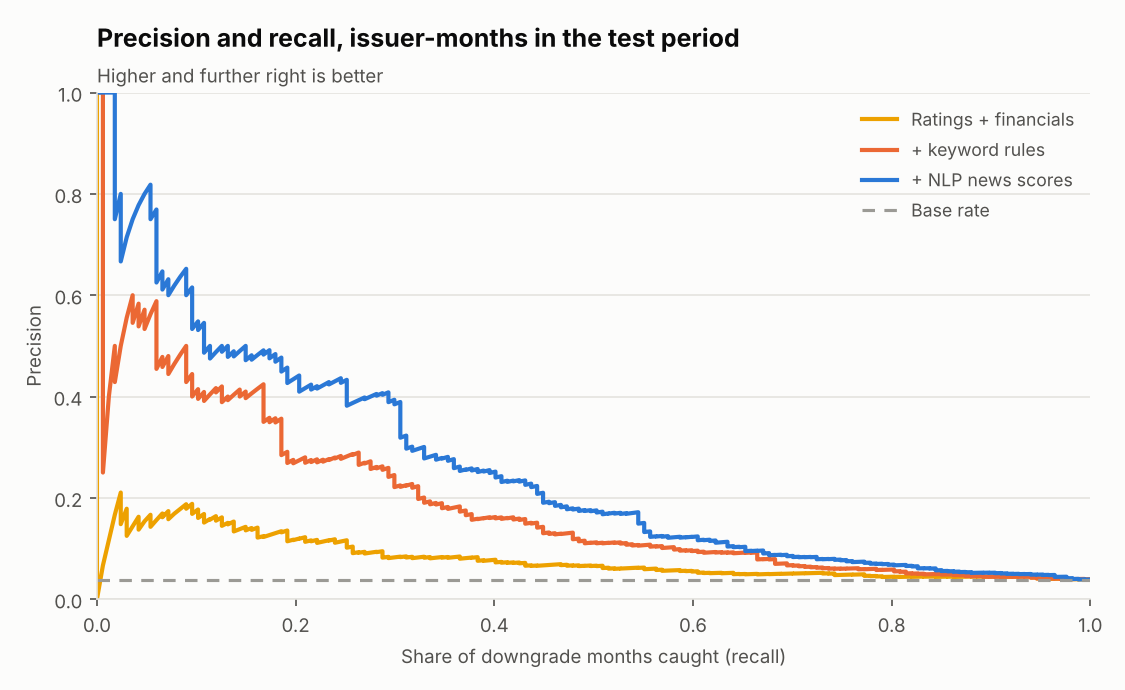

In [5]:
display(Image(filename=str(reporting.plot_model_comparison(run.evaluation, Path("outputs/figures/model_comparison.png")))))
display(Image(filename=str(reporting.plot_pr_curves(run.test, run.results, Path("outputs/figures/pr_curves.png")))))

Financials barely help in this data: they arrive two months after quarter end and are noisy. Keyword rules double the precision. The NLP scores add the rest: with the same 15 names a month, 29% of alerts were followed by a downgrade, against 25% for keywords and 13% for financials alone, and half of all downgrades were flagged in the three months before they happened. Shuffling the feature groups shows where the signal comes from.

In [6]:
explain.feature_group_importance(run.results[models.FULL], run.test)

,feature_group,pr_auc_drop,sd
3,NLP news scores,0.2074,0.0042
0,Rating and outlook,0.0740,0.0097
2,Keyword counts,0.0169,0.0099
1,Financials and share price,0.0032,0.0172


## One issuer, start to finish

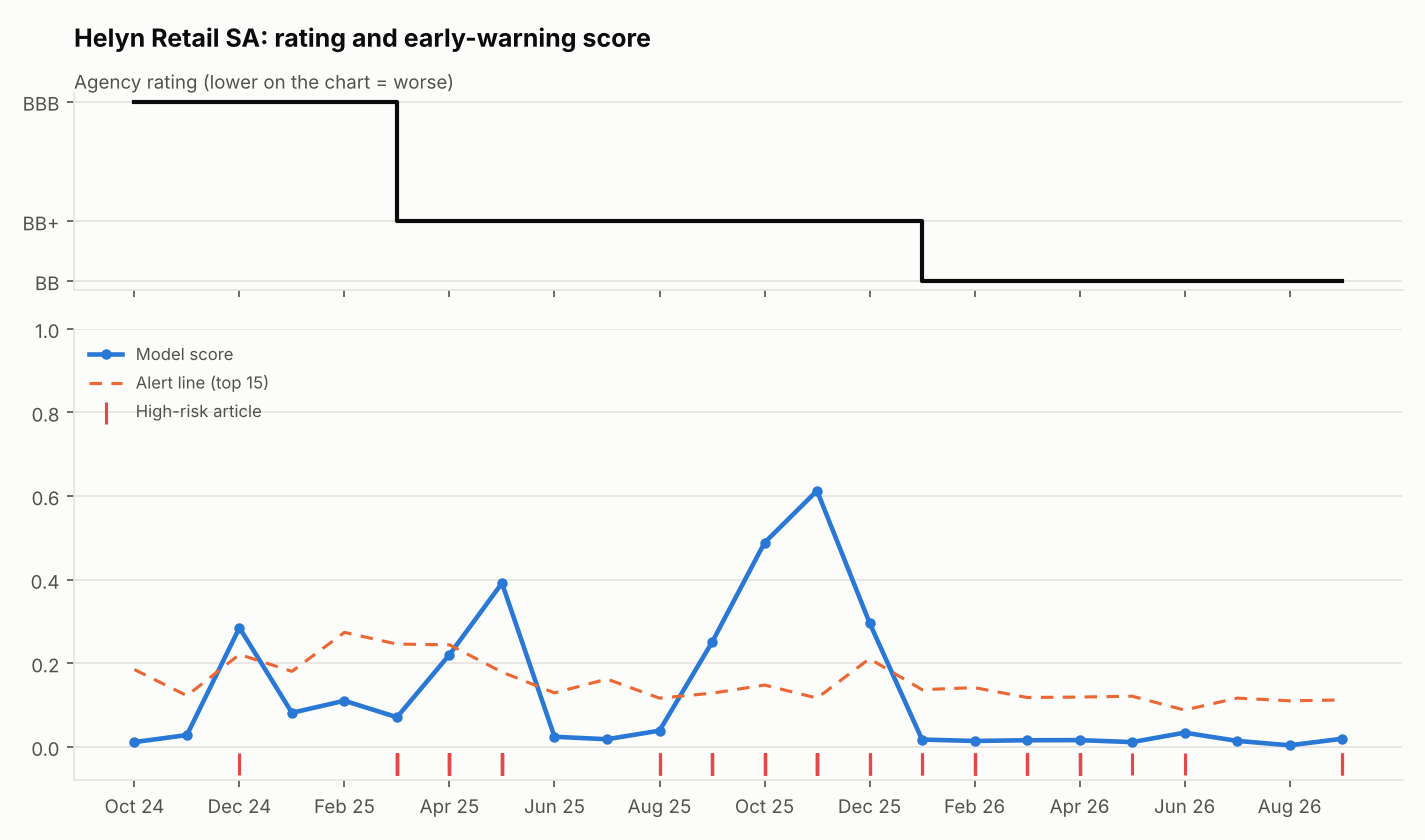

,issuer_id,month,action,from_rating,to_rating
694,ISS0300,2023-01,outlook negative,BBB+,BBB+
695,ISS0300,2023-04,downgrade,BBB+,BBB
696,ISS0300,2024-03,outlook stable,BBB,BBB
697,ISS0300,2025-03,downgrade,BBB,BB+
698,ISS0300,2025-12,outlook negative,BB+,BB+
699,ISS0300,2026-01,downgrade,BB+,BB


In [7]:
iss = pipeline.story_issuer(run)
name = tables["issuers"].set_index("issuer_id").loc[iss, "issuer_name"]
display(Image(filename=str(reporting.plot_issuer_story(run.panel, run.scored, run.scores_all, iss, name, run.alert_cut, Path("outputs/figures/issuer_story.png")))))
a = tables["rating_actions"]; display(a[a["issuer_id"] == iss])

The evidence an analyst would see for the first alert month: the three strongest articles and the words behind each score.

In [8]:
fl = models.alerts(run.test, run.results[models.FULL].scores)
first = fl[fl["issuer_id"] == iss]["month"].min()
print("First alert:", first)
explain.issuer_evidence(run.scored, iss, first, run.text_model)

First alert: 2025-09


,date,language,source,headline,p_article,why
51828,2025-09-25,en,Continental Business Review,Helyn Retail SA draws down credit line to shore up cash,0.856493,"cash, credit, facility, its revolving"
51584,2025-09-19,en,Continental Business Review,Helyn Retail SA seeks covenant waiver from lenders,0.803710,"covenant, credit, facility, its revolving"
51619,2025-09-20,en,Market Ledger,Helyn Retail SA bonds slide as investors grow nervous,0.728739,"bonds, credit, investors, fell"


## The live watchlist

For September 2026, the latest month, there is no label yet. The issuer model is refitted on every labelled month and the top 15 go to the analysts, each with its strongest article.

In [9]:
wl = pipeline.watchlist(run)
wl[["issuer_name", "sector", "rating", "outlook", "score", "headline"]]

,issuer_name,sector,rating,outlook,score,headline
0,Eldax Transport SpA,Transport & logistics,BBB-,negative,0.801885,Agency revises Eldax Transport SpA outlook to negative
1,Venax Property NV,Real estate,BB,negative,0.609117,Agency revises Venax Property NV outlook to negative
2,Dorvalt Foods SpA,Consumer goods,BBB,stable,0.522855,Dorvalt Foods SpA postpones bond issue amid weak investor demand
3,Graora Chemicals SE,Chemicals,BBB-,negative,0.365269,Agency revises Graora Chemicals SE outlook to negative
4,Calund Chemicals GmbH,Chemicals,A-,negative,0.300008,Ratingagentur senkt Ausblick für Calund Chemicals GmbH auf negativ
5,Torova Technik BV,Industrials,A-,negative,0.277789,Torova Technik BV bonds slide as investors grow nervous
6,Koryn Technik SAS,Industrials,BBB,negative,0.225233,Agency revises Koryn Technik SAS outlook to negative
7,Helica Industrie SE,Industrials,BBB-,stable,0.209771,Refinancing worries weigh on Helica Industrie SE
8,Altis Property GmbH,Real estate,B,stable,0.197126,Altis Property GmbH suspends dividend to preserve cash
9,Steica Pharma AG,Healthcare,B+,stable,0.189790,Steica Pharma AG verhandelt mit Banken über Covenants
